# Lights Out: exploring the data first

Before asking any big question, I wanted to get to know this dataset. What's in it, what's missing, and is there anything strange about Nigeria that's worth digging into?

This notebook is that first look. The questions it raised became the main analysis in `sql/`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11, "axes.titleweight": "bold", "axes.titlelocation": "left"})
NG, BD, MUTED = "#2a78d6", "#eb6834", "#b8b6b0"

df = pd.read_csv("../data/raw/owid-energy-data.csv")
print(f"{len(df):,} rows, {df.shape[1]} columns, years {df.year.min()} to {df.year.max()}")
df[["country", "year", "iso_code", "population", "electricity_generation", "per_capita_electricity"]].sample(5, random_state=1)

23,377 rows, 130 columns, years 1900 to 2025


,country,year,iso_code,population,electricity_generation,per_capita_electricity
13626,Netherlands,1919,NLD,6736779.0,NaN,NaN
17634,Portugal,1913,PRT,5918888.0,NaN,NaN
3640,CIS (EI),2021,NaN,NaN,1491.208,NaN
20831,Trinidad and Tobago,1956,TTO,761692.0,NaN,NaN
14139,Nigeria,1905,NGA,19614436.0,NaN,NaN


## What is one row?

One row is one place in one year. But "place" isn't always a country. Some rows are totals like "Africa" or "World". Those have no ISO code, or a made-up one starting with `OWID_`. If I mix them in with countries, I'd be counting people twice.

In [2]:
is_region = df.iso_code.isna() | df.iso_code.astype(str).str.startswith("OWID")
print("Regions and groups:", df[is_region].country.nunique())
print("Countries:", df[~is_region].country.nunique())
print("Some of the regions:", sorted(df[is_region].country.unique())[:12])
countries = df[~is_region].copy()

Regions and groups: 94
Countries: 220
Some of the regions: ['ASEAN (Ember)', 'Africa', 'Africa (EI)', 'Africa (EIA)', 'Africa (Ember)', 'Africa (Shift)', 'Asia', 'Asia (Ember)', 'Asia Pacific (EI)', 'Asia and Oceania (EIA)', 'Asia and Oceania (Shift)', 'Australia and New Zealand (EIA)']


## How far back does Nigeria's data go?

Different columns start in different years. I need to know where Nigeria's electricity numbers actually begin.

In [3]:
ng = countries[countries.country == "Nigeria"]
cols = ["population", "gdp", "electricity_generation", "per_capita_electricity", "gas_share_elec", "solar_share_elec", "net_elec_imports"]
pd.DataFrame({c: [ng.loc[ng[c].notna(), "year"].min(), ng.loc[ng[c].notna(), "year"].max()] for c in cols},
             index=["first year", "last year"]).T

,first year,last year
population,1900,2025
gdp,1950,2022
electricity_generation,2000,2025
per_capita_electricity,2000,2025
gas_share_elec,2000,2025
solar_share_elec,2000,2025
net_elec_imports,2000,2025


Electricity starts in **2000**, and GDP stops in **2022**. So the main analysis runs from 2000. Anything that needs income has to use 2022 or earlier.

## Is every year equally complete?

If the most recent year only covers some countries, comparing countries in that year would be unfair.

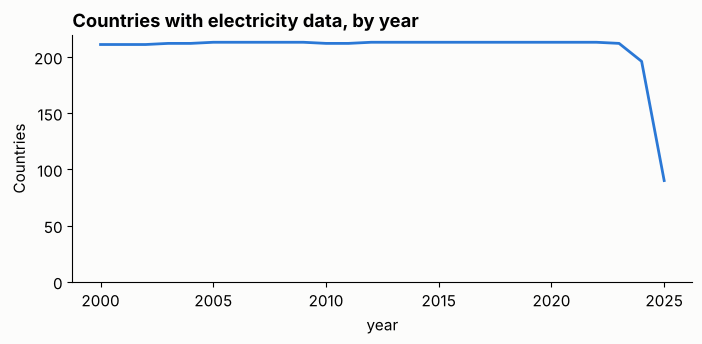

year
2022    213
2023    212
2024    196
2025     90
Name: per_capita_electricity, dtype: int64

In [4]:
coverage = countries[countries.year >= 2000].groupby("year").per_capita_electricity.apply(lambda s: s.notna().sum())
ax = coverage.plot(figsize=(8, 3.2), color=NG, linewidth=2)
ax.set_title("Countries with electricity data, by year")
ax.set_ylabel("Countries")
ax.set_ylim(0, None)
plt.show()
coverage.tail(4)

2025 drops to about 90 countries, against about 200 the year before. So **2024 is the last fair year** for comparing countries.

## Where does Nigeria sit?

A first look at how much grid electricity each person gets, across every country in 2024. The scale is logarithmic because the gap between the lowest and highest countries is huge.

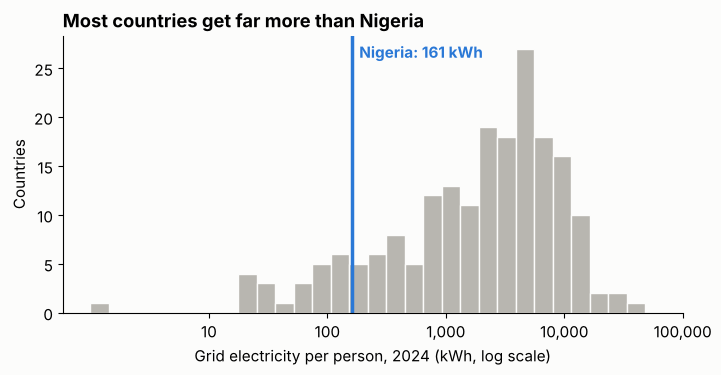

Nigeria is lower than 88% of countries


In [5]:
y24 = countries[(countries.year == 2024) & countries.per_capita_electricity.notna()]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(np.log10(y24.per_capita_electricity.clip(lower=1)), bins=30, color=MUTED, edgecolor="#fcfcfb")
ng24 = y24[y24.country == "Nigeria"].per_capita_electricity.iloc[0]
ax.axvline(np.log10(ng24), color=NG, linewidth=2.5)
ax.text(np.log10(ng24), ax.get_ylim()[1] * 0.92, f"  Nigeria: {ng24:.0f} kWh", color=NG, fontweight="bold")
ax.set_xticks([1, 2, 3, 4, 5], ["10", "100", "1,000", "10,000", "100,000"])
ax.set_xlabel("Grid electricity per person, 2024 (kWh, log scale)")
ax.set_ylabel("Countries")
ax.set_title("Most countries get far more than Nigeria")
plt.show()
print(f"Nigeria is lower than {(y24.per_capita_electricity > ng24).mean():.0%} of countries")

## Is that just because Nigeria isn't rich?

Richer countries use more electricity, so a low number on its own doesn't say much. The fairer question is whether Nigeria gets less power than **countries with a similar income**. I'll plot income per person against electricity per person for 2022, the last year with income data, and fit a line through all countries with at least a million people.

154 countries, correlation 0.92


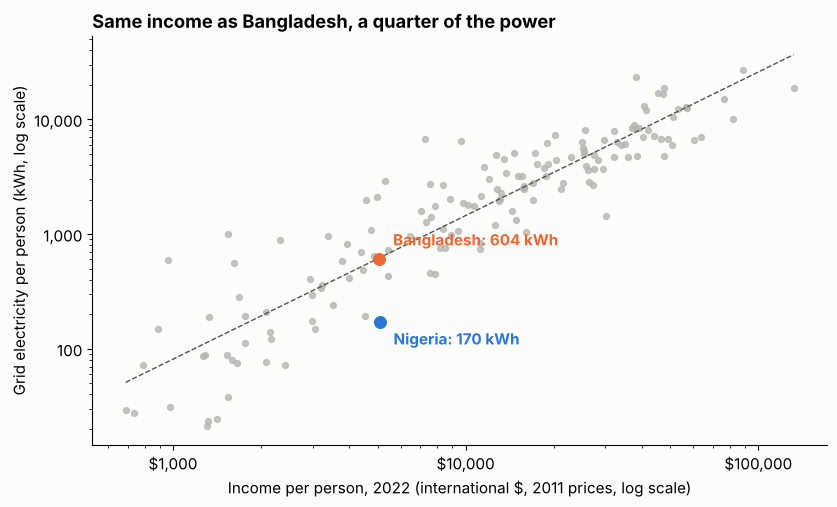

,gdp_per_person,per_capita_electricity,expected_kwh,share_of_expected
country,,,,
Nigeria,5083.77,170.29,621.09,0.27
Bangladesh,5066.24,603.66,618.41,0.98


In [6]:
y22 = countries[(countries.year == 2022) & countries.gdp.notna() & countries.per_capita_electricity.notna() & (countries.population >= 1e6)].copy()
y22["gdp_per_person"] = y22.gdp / y22.population
x, t = np.log10(y22.gdp_per_person), np.log10(y22.per_capita_electricity)
slope, intercept = np.polyfit(x, t, 1)
y22["expected_kwh"] = 10 ** (intercept + slope * x)
y22["share_of_expected"] = y22.per_capita_electricity / y22.expected_kwh
print(f"{len(y22)} countries, correlation {np.corrcoef(x, t)[0, 1]:.2f}")

fig, ax = plt.subplots(figsize=(8.5, 5.2))
ax.scatter(y22.gdp_per_person, y22.per_capita_electricity, s=18, color=MUTED, alpha=0.8)
xs = np.logspace(x.min(), x.max(), 50)
ax.plot(xs, 10 ** (intercept + slope * np.log10(xs)), color="#52514e", linewidth=1, linestyle="--")
for name, colour, dy in [("Nigeria", NG, -16), ("Bangladesh", BD, 10)]:
    r = y22[y22.country == name].iloc[0]
    ax.scatter(r.gdp_per_person, r.per_capita_electricity, s=70, color=colour, zorder=3)
    ax.annotate(f"{name}: {r.per_capita_electricity:.0f} kWh", (r.gdp_per_person, r.per_capita_electricity),
                xytext=(10, dy), textcoords="offset points", color=colour, fontweight="bold")
ax.set_xscale("log"); ax.set_yscale("log")
from matplotlib.ticker import FuncFormatter
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_xlabel("Income per person, 2022 (international $, 2011 prices, log scale)")
ax.set_ylabel("Grid electricity per person (kWh, log scale)")
ax.set_title("Same income as Bangladesh, a quarter of the power")
fig.tight_layout()
fig.savefig("../charts/income_vs_power.png", dpi=160)
plt.show()

y22.set_index("country").loc[["Nigeria", "Bangladesh"], ["gdp_per_person", "per_capita_electricity", "expected_kwh", "share_of_expected"]].round(2)

This is the most interesting thing in the dataset. Nigeria and Bangladesh had almost the same income per person in 2022. Bangladesh gets about what a country of its income usually gets. **Nigeria gets about a quarter.**

Which countries are furthest below the line?

In [7]:
ranked = y22.sort_values("share_of_expected")[["country", "gdp_per_person", "per_capita_electricity", "expected_kwh", "share_of_expected"]]
ranked["rank"] = range(1, len(ranked) + 1)
ranked.head(8).round(2)

,country,gdp_per_person,per_capita_electricity,expected_kwh,share_of_expected,rank
4353,Chad,1306.83,21.13,113.41,0.19,1
18824,Sierra Leone,1411.33,24.16,124.87,0.19,2
148,Afghanistan,1313.58,23.66,114.14,0.21,3
11397,Lithuania,30108.83,1434.19,5756.72,0.25,4
9050,Guinea-Bissau,1547.97,37.99,140.18,0.27,5
14256,Nigeria,5083.77,170.29,621.09,0.27,6
2615,Benin,2419.44,71.95,245.18,0.29,7
16943,Palestine,4538.22,192.26,538.82,0.36,8


Nigeria is **6th from the bottom of 154 countries**. One caution: this measures electricity *made* in the country, not *used*. Lithuania looks low because it imports most of its power. That doesn't explain Nigeria, though. Nigeria **sells** power to its neighbours, so it uses even less than it makes.

## Big drops in Nigeria's own numbers

Nigeria's output doesn't rise smoothly. Which years fell the most?

In [8]:
ng_window = ng[(ng.year >= 2000) & (ng.year <= 2024)].set_index("year")
change = ng_window.electricity_generation.pct_change().mul(100).round(1)
change.sort_values().head(4)

year
2017   -11.8
2024    -8.2
2008    -8.1
2003    -6.3
Name: electricity_generation, dtype: float64

Generation fell in 2003, every year from 2005 to 2009, and in 2017, 2019, 2022 and 2024. The data can't say why, but it means "it gets a bit better every year" isn't true. Progress keeps slipping back.

## What I took from this

1. **Use countries only, 2000 to 2024.** Regions double count, Nigeria starts in 2000, and 2025 is too thin.
2. **Compare Nigeria with Bangladesh.** Same starting point in 2000, same income in 2022, very different results. That's the story.
3. **Check whether population growth is eating the gains.** Nigeria makes more power than in 2000, so why is the per-person number so flat?
4. **Look at where the power comes from** and how much is sold abroad.
5. **Be clear this is grid power only.** Generators at homes and businesses aren't in here.

Those became the queries in `sql/02` to `sql/07`.